# Аналитическое решение, явная схема Эйлера и PINN

**Дата:** 2026-11-06.

**Цель.** Решить одну и ту же начально-краевую задачу тремя методами, количественно сравнить их и объяснить сильные и слабые стороны каждого.

$$
\frac{\partial u}{\partial t}=\beta\frac{\partial^2 u}{\partial x^2},\quad 0<x<1,\ 0<t\le T,\qquad \beta=10^{-5},\ T=12000,
$$
$$
u(x,0)=2x+\sin(2\pi x)+1,\qquad u(0,t)=1,\qquad u_x(1,t)=2.
$$

**Что значит «готово».** Есть все выводы, графики и таблицы из пунктов A1–D3. Эталон для ошибок это сошедшийся аналитический ряд, общая сетка содержит 101 точку по $x$. Наивный baseline это стационарный профиль $u_s(x)$: метод имеет смысл, только если он точнее $u_s$.

**Постоянный код** лежит в `src/`, здесь только вызовы и результаты. Обучение PINN занимает десятки минут, поэтому готовые запуски хранятся в `weights/` и загружаются из кэша. Чтобы обучить всё заново, удалите файлы из `weights/` и перезапустите ноутбук.

## 1. Настройка
Импорты, пути, стиль графиков. Цвет закреплён за методом: аналитика чёрная, Эйлер оранжевый, PINN синий, стационарный профиль серый.

In [1]:
from pathlib import Path
import sys, time

ROOT = Path.cwd().parent  # ноутбук запускается из notebooks/
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sympy as sp
import torch
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import NullFormatter
from scipy.integrate import quad

from src.analytic import exact_solution, series_coefficients, wave_numbers
from src.euler import diffusion_number, profile_at, solve_euler
from src.experiments import BOUNDARY_WEIGHTS, SEEDS, all_runs, ensure_trained, load_run
from src.metrics import max_abs_error, rmse
from src.pinn import DTYPE, PINNConfig, boundary_residuals, loss_terms, physics_residual, predict, sample_points
from src.problem import BETA, REPORT_TIMES, T, initial_condition, steady_state

torch.set_num_threads(1)  # один поток, как у кода Эйлера на numpy
TABLES = ROOT / "results" / "tables"
FIGURES = ROOT / "results" / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

COLORS = {"exact": "#0b0b0b", "euler": "#eb6834", "pinn": "#2a78d6", "steady": "#8a8984", "aqua": "#1baf7a", "yellow": "#eda100"}
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.float_format", lambda v: f"{v:.3e}")
pd.set_option("display.width", 160)

X_EVAL = np.linspace(0.0, 1.0, 101)  # общая сетка для всех сравнений
ERROR_TIMES = (3000.0, 6000.0, 12000.0)


def reference(x, t):
    # При t = 0 ряд сходится медленно, а точный профиль известен, поэтому берём его
    return initial_condition(np.asarray(x)) if t == 0 else exact_solution(x, t)


def save_table(frame, name):
    frame.to_csv(TABLES / f"{name}.csv", index=False)
    display(frame)


def save_figure(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()


print("torch", torch.__version__, "| numpy", np.__version__)

torch 2.14.1 | numpy 2.5.4


## 2. Несогласованность в углу $(x,t)=(1,0)$
Начальный профиль и условие Неймана в этой точке противоречат друг другу:

$$u_x(x,0)=2+2\pi\cos(2\pi x)\ \Rightarrow\ u_x(1,0)=2+2\pi\approx 8.283,\quad\text{а граница требует } u_x(1,t)=2.$$

**Что это значит для сравнения на ранних временах:**
- Точное решение при $t>0$ гладкое, но у самого угла при малых $t$ быстро меняется наклон. Разрыв наклона размазывается в тонкий пограничный слой толщиной порядка $\sqrt{\beta t}$: при $t=100$ это всего $0.03$, а при $t=3000$ уже $0.17$.
- Ряд при $t=0$ сходится медленно ($b_n\sim 1/n^2$), поэтому при $t=0$ эталоном берём сам начальный профиль.
- Сетка с шагом $\Delta x=0.025$ при $t\lesssim 100$ этот слой почти не разрешает.
- PINN это гладкая функция, и в углу она не может выполнить оба условия сразу. Её ошибка здесь не означает, что сеть плохая: требования в этой точке несовместимы.

Левый угол согласован: $u(0,0)=1$. Количественно ранние времена разобраны в разделе D2.

In [2]:
print("u_x(1, 0) по начальному профилю =", 2 + 2 * np.pi, "| требует граница = 2 | разрыв =", 2 * np.pi)
print("левый угол: u(0, 0) =", initial_condition(np.array(0.0)), "| требует граница = 1")

u_x(1, 0) по начальному профилю = 8.283185307179586 | требует граница = 2 | разрыв = 6.283185307179586
левый угол: u(0, 0) = 1.0 | требует граница = 1


---
# Часть A. Аналитическое решение

## A1. Стационарное решение
Из $u_{s,xx}=0$ следует $u_s(x)=Cx+D$. Условия дают $u_s(0)=D=1$ и $u_s'(1)=C=2$:

$$\boxed{u_s(x)=2x+1.}$$

**Физический смысл.** Это распределение температуры, к которому стержень придёт при $t\to\infty$. Левый конец держится при температуре 1, а через правый задан постоянный градиент 2 (постоянный поток тепла). В равновесии температура перестаёт меняться, поэтому поток $-\beta u_x$ один и тот же в каждом сечении, и профиль линейный. Начальное условие на $u_s$ не влияет: вся память о нём содержится в переходной части.

## A2. Задача для $v=u-u_s$
Подставим $u=v+u_s$. Так как $u_s$ не зависит от $t$ и $u_{s,xx}=0$:

$$v_t=u_t=\beta u_{xx}=\beta(v_{xx}+u_{s,xx})=\beta v_{xx}.$$

Граничные условия становятся однородными:
$$v(0,t)=u(0,t)-u_s(0)=1-1=0,\qquad v_x(1,t)=u_x(1,t)-u_s'(1)=2-2=0.$$

Начальное условие:
$$v(x,0)=2x+\sin(2\pi x)+1-(2x+1)=\sin(2\pi x).$$

## A3. Разделение переменных
Ищем $v=X(x)\Theta(t)\not\equiv0$. Подстановка в $v_t=\beta v_{xx}$ даёт

$$\frac{\Theta'}{\beta\Theta}=\frac{X''}{X}=-\lambda.$$

Левая часть зависит только от $t$, средняя только от $x$, поэтому обе равны константе. Получаем две задачи: $\Theta'=-\beta\lambda\Theta$ и $X''+\lambda X=0$, $X(0)=0$, $X'(1)=0$.

**Возможные $\lambda$:**
- $\lambda<0$: $X=A\,\mathrm{sh}(\mu x)$ из $X(0)=0$, тогда $X'(1)=A\mu\,\mathrm{ch}\,\mu=0$ только при $A=0$.
- $\lambda=0$: $X=Ax$, тогда $X'(1)=A=0$.
- $\lambda=k^2>0$: $X=A\sin(kx)$, условие $X'(1)=Ak\cos k=0$ даёт $\cos k=0$, то есть $k_n=(n+\tfrac12)\pi$, $n=0,1,\dots$

Отсюда $\Theta_n=e^{-\beta k_n^2t}$, и суперпозиция решений даёт

$$v(x,t)=\sum_{n=0}^{\infty}b_n\sin(k_nx)\,e^{-\beta k_n^2t},\qquad k_n=\left(n+\tfrac12\right)\pi.$$

**Формула коэффициентов.** Функции $\sin(k_nx)$ ортогональны на $[0,1]$. При $n\ne m$:

$$\int_0^1\sin(k_nx)\sin(k_mx)\,dx=\frac12\left[\frac{\sin(k_n-k_m)}{k_n-k_m}-\frac{\sin(k_n+k_m)}{k_n+k_m}\right]=0,$$

потому что $k_n-k_m=(n-m)\pi$ и $k_n+k_m=(n+m+1)\pi$ это целые кратные $\pi$, и оба синуса равны нулю. При $n=m$: $\int_0^1\sin^2(k_nx)\,dx=\tfrac12-\tfrac{\sin 2k_n}{4k_n}=\tfrac12$, потому что $\sin 2k_n=\sin((2n+1)\pi)=0$. Умножая $v(x,0)=\sum b_n\sin(k_nx)$ на $\sin(k_mx)$ и интегрируя, получаем

$$b_n=2\int_0^1v(x,0)\sin(k_nx)\,dx.$$

**Вычисление интеграла.** По формуле произведения синусов:

$$b_n=2\int_0^1\sin(2\pi x)\sin(k_nx)\,dx=\int_0^1\big[\cos((2\pi-k_n)x)-\cos((2\pi+k_n)x)\big]dx=\frac{\sin(2\pi-k_n)}{2\pi-k_n}-\frac{\sin(2\pi+k_n)}{2\pi+k_n}.$$

Так как $\sin(2\pi\mp k_n)=\mp\sin k_n$ и $\sin k_n=(-1)^n$:

$$\boxed{b_n=-\sin k_n\,\frac{4\pi}{4\pi^2-k_n^2}=\frac{(-1)^{n+1}\,4\pi}{4\pi^2-k_n^2}=\frac{(-1)^{n+1}\,4}{\pi\left(4-(n+\frac12)^2\right)}.}$$

Знаменатель не обращается в ноль: $n+\tfrac12\ne2$ при целом $n$, то есть $\sin(2\pi x)$ не является собственной функцией этой задачи. Поэтому разложение содержит много мод, а не одну. Коэффициенты убывают как $1/n^2$: это след разрыва производной в углу из раздела 2.

Проверяем формулу двумя независимыми способами: символьным интегрированием и численной квадратурой.

In [3]:
# Сверка формулы для b_n с символьным и численным интегрированием
x_sym = sp.symbols("x", real=True)
rows = []
formula = series_coefficients(8)
for n, k in enumerate(wave_numbers(8)):
    k_sym = (sp.Integer(n) + sp.Rational(1, 2)) * sp.pi
    symbolic = 2 * sp.integrate(sp.sin(2 * sp.pi * x_sym) * sp.sin(k_sym * x_sym), (x_sym, 0, 1))
    numeric = 2 * quad(lambda z: np.sin(2 * np.pi * z) * np.sin(k * z), 0, 1)[0]
    rows.append({"n": n, "k_n": k, "b_n (формула)": formula[n], "b_n (sympy)": float(symbolic),
                 "b_n (квадратура)": numeric, "|формула - sympy|": abs(formula[n] - float(symbolic))})
save_table(pd.DataFrame(rows), "a3_coefficients")

,n,k_n,b_n (формула),b_n (sympy),b_n (квадратура),|формула - sympy|
0,0,1.571e+00,-3.395e-01,-3.395e-01,-3.395e-01,5.551e-17
1,1,4.712e+00,7.276e-01,7.276e-01,7.276e-01,1.110e-16
2,2,7.854e+00,5.659e-01,5.659e-01,5.659e-01,0.000e+00
3,3,1.100e+01,-1.543e-01,-1.543e-01,-1.543e-01,0.000e+00
4,4,1.414e+01,7.835e-02,7.835e-02,7.835e-02,0.000e+00
5,5,1.728e+01,-4.850e-02,-4.850e-02,-4.850e-02,1.388e-17
6,6,2.042e+01,3.329e-02,3.329e-02,3.329e-02,0.000e+00
7,7,2.356e+01,-2.437e-02,-2.437e-02,-2.437e-02,6.939e-18


**Вывод.** Формула совпала с `sympy` и квадратурой до ошибок округления. Наибольшие вклады дают моды $n=1$ и $n=2$, а не нулевая, потому что волновое число $2\pi\approx6.28$ начального профиля лежит между $k_1\approx4.71$ и $k_2\approx7.85$.

## A4. Усечённый ряд и сходимость
Считаем ряд при $N=10,\dots,4000$ и сравниваем с рядом из $N=20000$ слагаемых, а при $t=0$ ещё и с точным начальным профилем. Ожидание до расчёта: при $t>0$ хватит нескольких слагаемых, так как $e^{-\beta k_n^2t}$ гасит высокие моды, а при $t=0$ ошибка будет падать медленно, примерно как $1/N$.

,N,"t=0, против u(x,0)","t=3000, против N=20000","t=6000, против N=20000","t=12000, против N=20000"
0,10,1.289e-01,4.441e-16,4.441e-16,4.441e-16
1,50,2.548e-02,0.000e+00,0.000e+00,0.000e+00
2,100,1.273e-02,0.000e+00,0.000e+00,0.000e+00
3,200,6.366e-03,0.000e+00,0.000e+00,0.000e+00
4,1000,1.273e-03,0.000e+00,0.000e+00,0.000e+00
5,2000,6.366e-04,0.000e+00,0.000e+00,0.000e+00
6,4000,3.183e-04,0.000e+00,0.000e+00,0.000e+00


Множитель exp(-beta k_n^2 t):


,t=3000,t=6000,t=12000
n=0,0.9287,0.8624,0.7437
n=1,0.5137,0.2638,0.0696
n=2,0.1572,0.0247,0.0006
n=3,0.0266,0.0007,0.0000
n=4,0.0025,0.0000,0.0000


Характерное время первой моды 1 / (beta k_0^2) = 40528 | T = 12000


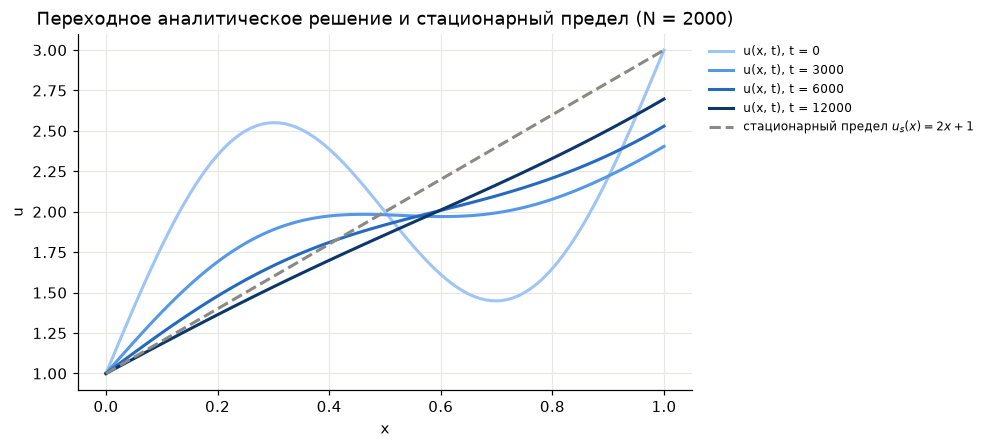

,t,max|u - u_s| = max|v|,"RMSE(u, u_s)"
0,0.000e+00,1.000e+00,7.036e-01
1,3.000e+03,5.958e-01,3.522e-01
2,6.000e+03,4.707e-01,2.488e-01
3,1.200e+04,3.028e-01,1.825e-01


In [4]:
rows = []
for n_terms in (10, 50, 100, 200, 1000, 2000, 4000):
    row = {"N": n_terms, "t=0, против u(x,0)": max_abs_error(exact_solution(X_EVAL, 0.0, n_terms), initial_condition(X_EVAL))}
    for t in REPORT_TIMES[1:]:
        row[f"t={t:.0f}, против N=20000"] = max_abs_error(exact_solution(X_EVAL, t, n_terms), exact_solution(X_EVAL, t, 20000))
    rows.append(row)
save_table(pd.DataFrame(rows), "a4_series_convergence")

# Насколько быстро гаснут первые моды к разным моментам времени
k = wave_numbers(5)
print("Множитель exp(-beta k_n^2 t):")
display(pd.DataFrame({f"t={t:.0f}": np.exp(-BETA * k**2 * t) for t in REPORT_TIMES[1:]}, index=[f"n={n}" for n in range(5)]).style.format("{:.4f}"))
print("Характерное время первой моды 1 / (beta k_0^2) =", round(1 / (BETA * k[0] ** 2)), "| T =", int(T))

shades = ["#9ec5f4", "#5598e7", "#256abf", "#0d366b"]
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for t, color in zip(REPORT_TIMES, shades):
    ax.plot(X_EVAL, exact_solution(X_EVAL, t, 2000), color=color, label=f"u(x, t), t = {t:.0f}")
ax.plot(X_EVAL, steady_state(X_EVAL), "--", color=COLORS["steady"], label="стационарный предел $u_s(x)=2x+1$")
ax.set(xlabel="x", ylabel="u", title="Переходное аналитическое решение и стационарный предел (N = 2000)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8)
save_figure(fig, "a4_analytic_profiles")

rows = [{"t": t, "max|u - u_s| = max|v|": max_abs_error(reference(X_EVAL, t), steady_state(X_EVAL)),
         "RMSE(u, u_s)": rmse(reference(X_EVAL, t), steady_state(X_EVAL))} for t in REPORT_TIMES]
save_table(pd.DataFrame(rows), "a4_distance_from_steady_state")

**Вывод.**
- **Сходимость.** При $t\ge3000$ уже $N=10$ даёт машинную точность: множитель $e^{-\beta k_n^2t}$ убивает старшие моды. При $t=0$ ошибка убывает как $\approx1.27/N$ (удвоение $N$ вдвое снижает ошибку), что согласуется с $b_n\sim1/n^2$. Поэтому $N=50$ при $t=0$ даёт ещё $2.5\cdot10^{-2}$, и при $t=0$ эталоном служит сам начальный профиль. В сравнениях используется $N=2000$.
- **Переходное решение и предел.** Это разные функции: при $t=T$ от $u_s$ остаётся $\max|v|=0.30$, RMSE $0.18$. Характерное время первой моды $1/(\beta k_0^2)\approx40500$ заметно больше $T=12000$, её множитель при $T$ равен всего $0.74$. До 1% от начальной амплитуды этой моды нужно $t\approx190000$. Значит, на заданном интервале стационарный профиль не достигается и служит только baseline.

---
# Часть B. Явная схема Эйлера

## B1. Вывод схемы и устойчивость
Сетка: $x_j=j\Delta x$, $t_m=m\Delta t$, $U_j^m\approx u(x_j,t_m)$. Заменим производные разностями:

$$u_t(x_j,t_m)=\frac{U_j^{m+1}-U_j^m}{\Delta t}+O(\Delta t),\qquad u_{xx}(x_j,t_m)=\frac{U_{j-1}^m-2U_j^m+U_{j+1}^m}{(\Delta x)^2}+O(\Delta x^2).$$

Подставляя в уравнение и выражая новый слой:

$$U_j^{m+1}=U_j^m+s\,(U_{j-1}^m-2U_j^m+U_{j+1}^m),\qquad s=\frac{\beta\Delta t}{(\Delta x)^2}.$$

**Устойчивость (анализ фон Неймана).** Подставим гармонику $U_j^m=G^me^{\mathrm{i}j\theta}$:

$$G=1+s(e^{-\mathrm{i}\theta}-2+e^{\mathrm{i}\theta})=1-4s\sin^2\frac{\theta}{2}.$$

Условие $|G|\le1$ для всех $\theta$ равносильно $\boxed{s\le\tfrac12.}$ Самая опасная мода это пилообразная с $\theta=\pi$, у неё $G=1-4s$.

**Для заданной сетки** $\Delta x=1/40$, $\Delta t=20$:
$$s=\frac{10^{-5}\cdot20}{(1/40)^2}=10^{-5}\cdot20\cdot1600=0.32\le0.5,$$
схема устойчива.

**Граничные условия.** Слева $U_0^{m+1}=1$. Справа односторонняя разность первого порядка:

$$\frac{U_J^{m+1}-U_{J-1}^{m+1}}{\Delta x}=2\ \Rightarrow\ U_J^{m+1}=U_{J-1}^{m+1}+2\Delta x.$$

## B2. Реализация
Код схемы написан вручную, без библиотечных решателей: [src/euler.py](../src/euler.py). Он занимает один цикл по времени с векторным обновлением внутренних узлов, затем задаются обе границы.

In [5]:
print("s =", diffusion_number(40, 600))
x_c, t_c, U_c = solve_euler(n_intervals=40, n_steps=600, neumann_order=1)
print("узлов по x:", x_c.size, "| слоёв по t:", t_c.size, "| dx =", x_c[1] - x_c[0], "| dt =", t_c[1] - t_c[0])
print("диапазон решения:", U_c.min().round(4), "...", U_c.max().round(4))

s = 0.32
узлов по x: 41 | слоёв по t: 601 | dx = 0.025 | dt = 20.0
диапазон решения: 1.0 ... 3.0


## B3. Сравнение с аналитикой и карта решения
На каждом графике своя сетка времени, цвет закреплён за методом. Численное решение на 41 узле линейно интерполируем на общую сетку из 101 точки. Интерполяция сама вносит ошибку порядка $O(\Delta x^2)$, поэтому оцениваем её отдельно: интерполируем точное решение с тех же 41 узла.

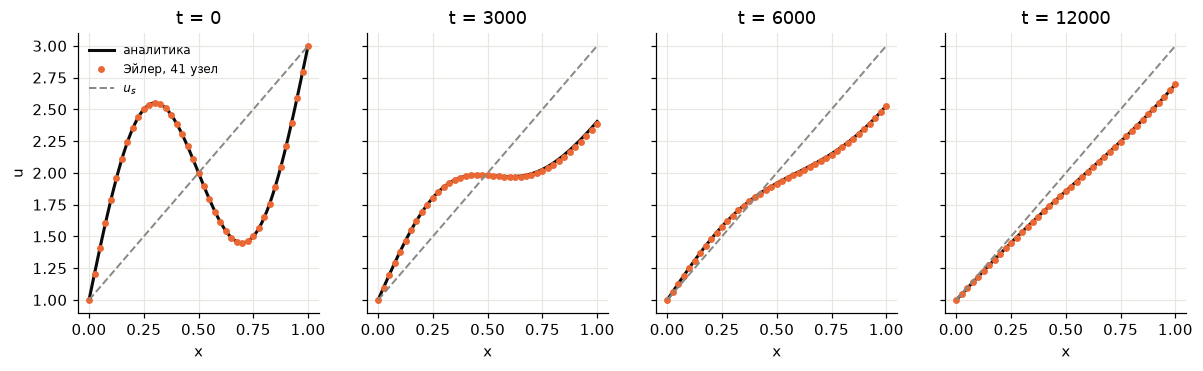

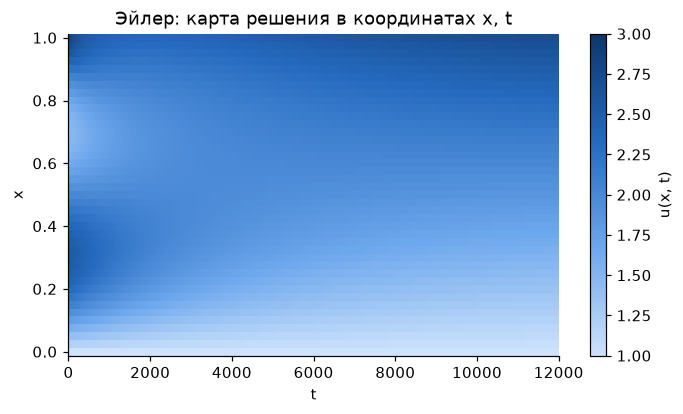

,t,max ошибка Эйлера,RMSE Эйлера,max ошибка только интерполяции
0,0.000e+00,2.951e-03,1.583e-03,2.951e-03
1,3.000e+03,1.995e-02,9.337e-03,9.165e-04
2,6.000e+03,8.519e-03,5.173e-03,3.384e-04
3,1.200e+04,3.381e-03,2.284e-03,1.293e-04


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3), sharey=True)
for ax, t in zip(axes, REPORT_TIMES):
    ax.plot(X_EVAL, reference(X_EVAL, t), color=COLORS["exact"], label="аналитика")
    ax.plot(x_c, profile_at(t_c, U_c, t), "o", ms=3.5, color=COLORS["euler"], label="Эйлер, 41 узел")
    ax.plot(X_EVAL, steady_state(X_EVAL), "--", lw=1.3, color=COLORS["steady"], label="$u_s$")
    ax.set(title=f"t = {t:.0f}", xlabel="x")
axes[0].set_ylabel("u")
axes[0].legend(loc="upper left", fontsize=8)
save_figure(fig, "b3_euler_vs_analytic")

fig, ax = plt.subplots(figsize=(7.2, 3.8))
image = ax.pcolormesh(t_c, x_c, U_c.T, cmap=BLUES, shading="auto")
fig.colorbar(image, ax=ax, label="u(x, t)")
ax.set(xlabel="t", ylabel="x", title="Эйлер: карта решения в координатах x, t")
ax.grid(False)
save_figure(fig, "b3_euler_heatmap")

rows = []
for t in REPORT_TIMES:
    euler_on_eval = np.interp(X_EVAL, x_c, profile_at(t_c, U_c, t))
    interp_only = np.interp(X_EVAL, x_c, reference(x_c, t))
    rows.append({"t": t, "max ошибка Эйлера": max_abs_error(euler_on_eval, reference(X_EVAL, t)),
                 "RMSE Эйлера": rmse(euler_on_eval, reference(X_EVAL, t)),
                 "max ошибка только интерполяции": max_abs_error(interp_only, reference(X_EVAL, t))})
save_table(pd.DataFrame(rows), "b3_euler_errors")

**Вывод.** На глаз схема совпадает с аналитикой на всех четырёх профилях. RMSE падает со временем: $9.3\cdot10^{-3}$, $5.2\cdot10^{-3}$, $2.3\cdot10^{-3}$. Это в 38–80 раз лучше стационарного baseline (0.35, 0.25, 0.18). Вклад интерполяции мал при $t>0$: при $t=3000$ она даёт $9\cdot10^{-4}$ из $2\cdot10^{-2}$. При $t=0$ в узлах ошибка равна нулю, а вся ошибка на общей сетке, $3\cdot10^{-3}$, создаётся интерполяцией.

## B4. Измельчение сетки и влияние условия Неймана первого порядка
Держим $s=0.32$ постоянным: при уменьшении $\Delta x$ в 2 раза $\Delta t$ уменьшаем в 4 раза, и условие устойчивости выполнено на всех сетках. Кроме заданной схемы считаем контрольный вариант с тем же внутренним шаблоном, но с условием Неймана второго порядка через фиктивный узел $U_{J+1}=U_{J-1}+4\Delta x$. Отличие только в правой границе, поэтому разница вариантов показывает вклад именно этого приближения.

**Ожидание по Тейлору.** Разложение вокруг $x=1$ даёт:
$$\frac{u(1,t)-u(1-\Delta x,t)}{\Delta x}=u_x(1,t)-\frac{\Delta x}{2}u_{xx}(1,t)+O(\Delta x^2).$$
Значит, условие $U_J-U_{J-1}=2\Delta x$ на самом деле ставит наклон 2 в середине последней ячейки, и ошибка границы равна $\frac{\Delta x}{2}u_{xx}(1,t)$, то есть имеет порядок $O(\Delta x)$. Внутренний шаблон при $s=\mathrm{const}$ точнее: $O(\Delta t)+O(\Delta x^2)=O(\Delta x^2)$. Поэтому первый порядок границы должен определять всю ошибку.

,порядок Неймана,dx,dt,s,"время, с",max t=3000,RMSE t=3000,max t=6000,RMSE t=6000,max t=12000,RMSE t=12000,"порядок p, RMSE t=3000","порядок p, RMSE t=6000","порядок p, RMSE t=12000"
0,1,2.500e-02,2.000e+01,3.200e-01,1.981e-03,1.995e-02,9.337e-03,8.519e-03,5.173e-03,3.381e-03,2.284e-03,NaN,NaN,NaN
1,1,1.250e-02,5.000e+00,3.200e-01,7.860e-03,1.121e-02,5.262e-03,5.093e-03,3.093e-03,2.097e-03,1.431e-03,8.273e-01,7.421e-01,6.745e-01
2,1,6.250e-03,1.250e+00,3.200e-01,3.374e-02,5.907e-03,2.777e-03,2.751e-03,1.675e-03,1.160e-03,8.013e-04,9.222e-01,8.852e-01,8.364e-01
3,1,3.125e-03,3.125e-01,3.200e-01,1.407e-01,3.028e-03,1.424e-03,1.426e-03,8.693e-04,6.085e-04,4.232e-04,9.630e-01,9.458e-01,9.211e-01
4,2,2.500e-02,2.000e+01,3.200e-01,2.122e-03,1.562e-03,9.889e-04,1.182e-03,6.502e-04,8.066e-04,4.125e-04,NaN,NaN,NaN
5,2,1.250e-02,5.000e+00,3.200e-01,8.364e-03,3.891e-04,2.473e-04,2.952e-04,1.626e-04,2.014e-04,1.031e-04,2.000e+00,2.000e+00,2.000e+00
6,2,6.250e-03,1.250e+00,3.200e-01,3.586e-02,9.772e-05,6.182e-05,7.384e-05,4.065e-05,5.042e-05,2.578e-05,2.000e+00,2.000e+00,2.000e+00
7,2,3.125e-03,3.125e-01,3.200e-01,1.544e-01,2.431e-05,1.546e-05,1.845e-05,1.016e-05,1.259e-05,6.444e-06,2.000e+00,2.000e+00,2.000e+00


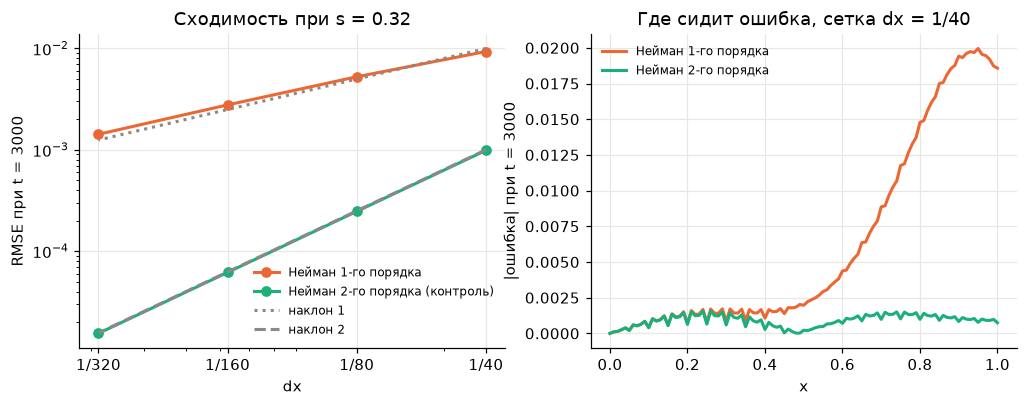

dx = 1/80, dt = 20: s = 1.28 | max|U| в конце = nan


In [7]:
# Сетки с одинаковым s = 0.32. В памяти храним только 4 нужных слоя
rows, errors_by_order = [], {1: [], 2: []}
for order in (1, 2):
    for n_intervals, n_steps in ((40, 600), (80, 2400), (160, 9600), (320, 38400)):
        start = time.perf_counter()
        x, ts, U = solve_euler(n_intervals, n_steps, neumann_order=order, store_every=n_steps // 4)
        elapsed = time.perf_counter() - start
        row = {"порядок Неймана": order, "dx": 1 / n_intervals, "dt": T / n_steps,
               "s": diffusion_number(n_intervals, n_steps), "время, с": elapsed}
        for t in ERROR_TIMES:
            pred = np.interp(X_EVAL, x, profile_at(ts, U, t))
            row[f"max t={t:.0f}"] = max_abs_error(pred, reference(X_EVAL, t))
            row[f"RMSE t={t:.0f}"] = rmse(pred, reference(X_EVAL, t))
        rows.append(row)
        errors_by_order[order].append(row)
refine = pd.DataFrame(rows)
# Наблюдаемый порядок p = log2(ошибка на грубой / ошибка на вдвое более мелкой)
for t in ERROR_TIMES:
    refine[f"порядок p, RMSE t={t:.0f}"] = refine.groupby("порядок Неймана")[f"RMSE t={t:.0f}"].transform(lambda s_: np.log2(s_.shift(1) / s_))
save_table(refine, "b4_euler_refinement")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
for order, color, label in ((1, COLORS["euler"], "Нейман 1-го порядка"), (2, COLORS["aqua"], "Нейман 2-го порядка (контроль)")):
    part = refine[refine["порядок Неймана"] == order]
    axes[0].loglog(part["dx"], part["RMSE t=3000"], "o-", color=color, label=label)
axes[0].loglog(refine["dx"][:4], 0.4 * refine["dx"][:4], ":", color=COLORS["steady"], label="наклон 1")
axes[0].loglog(refine["dx"][:4], 1.6 * refine["dx"][:4] ** 2, "--", color=COLORS["steady"], label="наклон 2")
axes[0].set(xlabel="dx", ylabel="RMSE при t = 3000", title="Сходимость при s = 0.32")
axes[0].xaxis.set_minor_formatter(NullFormatter())
axes[0].set_xticks([1 / 320, 1 / 160, 1 / 80, 1 / 40], ["1/320", "1/160", "1/80", "1/40"])
axes[0].legend(fontsize=8)

for order, color, label in ((1, COLORS["euler"], "Нейман 1-го порядка"), (2, COLORS["aqua"], "Нейман 2-го порядка")):
    x, ts, U = solve_euler(40, 600, neumann_order=order, store_every=150)
    axes[1].plot(X_EVAL, np.abs(np.interp(X_EVAL, x, profile_at(ts, U, 3000.0)) - reference(X_EVAL, 3000.0)), color=color, label=label)
axes[1].set(xlabel="x", ylabel="|ошибка| при t = 3000", title="Где сидит ошибка, сетка dx = 1/40")
axes[1].legend(fontsize=8)
save_figure(fig, "b4_refinement")

# Проверка условия устойчивости: шаг по времени оставляем, а сетку по x измельчаем
with np.errstate(over="ignore", invalid="ignore"):
    _, _, unstable = solve_euler(80, 600, neumann_order=1, store_every=600)
print("dx = 1/80, dt = 20: s =", diffusion_number(80, 600), "| max|U| в конце =", np.abs(unstable[-1]).max())

**Вывод.**
- **Заданная схема.** При каждом измельчении RMSE уменьшается почти вдвое. Наблюдаемый порядок при $t=3000$: 0.83, 0.92, 0.96, то есть стремится к 1, как и предсказал Тейлор. На грубых сетках порядок ниже 1, потому что множитель $u_{xx}(1,t)$ велик в начале и сетка ещё не вышла на асимптотический режим.
- **Причина первого порядка.** Контрольная схема отличается только правой границей и даёт порядок ровно 2.00 при всех $t$. Значит, порядок ошибки определяет именно условие Неймана: одна граничная формула портит точность всего решения, потому что ошибка потока диффузией расходится внутрь отрезка. На правом графике при $t=3000$ она занимает уже правую половину отрезка, а в левой половине обе схемы почти совпадают. Зубцы на линиях создаёт интерполяция между узлами.
- **Практический вес.** На той же сетке $\Delta x=1/40$ и почти за то же время ошибка второго порядка в 9 раз меньше ($9.9\cdot10^{-4}$ против $9.3\cdot10^{-3}$ при $t=3000$). Схема первого порядка на сетке $1/320$ всё ещё хуже второго порядка на $1/40$ ($1.4\cdot10^{-3}$), хотя считается примерно в 70 раз дольше.
- **Устойчивость.** При $\Delta x=1/80$ и прежнем $\Delta t=20$ получается $s=1.28>0.5$, и решение разваливается до `nan`. Измельчать только $x$ нельзя, $\Delta t$ должен падать как $\Delta x^2$.

---
# Часть C. Physics-Informed Neural Network

## C1. Масштабированная невязка и функции потерь
Вводим $\tau=t/T\in[0,1]$. По правилу цепочки $\dfrac{\partial u_\theta}{\partial t}=\dfrac{\partial u_\theta}{\partial\tau}\dfrac{d\tau}{dt}=\dfrac1T\dfrac{\partial u_\theta}{\partial\tau}$. Производная по $x$ не меняется. Подставляя в уравнение, получаем

$$r_\theta(x,\tau)=\frac1T\frac{\partial u_\theta}{\partial\tau}-\beta\frac{\partial^2u_\theta}{\partial x^2}.$$

**Функции потерь.** Для точек коллокации $(x_i^r,\tau_i^r)$, начальных $x_i^{0}$ и граничных $\tau_i^b$:

$$L_{\text{phys}}=\frac1{N_r}\sum_{i=1}^{N_r}r_\theta(x_i^r,\tau_i^r)^2,$$
$$L_{\text{IC}}=\frac1{N_0}\sum_{i=1}^{N_0}\big(u_\theta(x_i^0,0)-2x_i^0-\sin(2\pi x_i^0)-1\big)^2,$$
$$L_{\text{D}}=\frac1{N_b}\sum_{i=1}^{N_b}\big(u_\theta(0,\tau_i^b)-1\big)^2,\qquad L_{\text{N}}=\frac1{N_b}\sum_{i=1}^{N_b}\big(\partial_xu_\theta(1,\tau_i^b)-2\big)^2,$$
$$L=\lambda_{\text{phys}}L_{\text{phys}}+\lambda_{\text{IC}}L_{\text{IC}}+\lambda_{\text{D}}L_{\text{D}}+\lambda_{\text{N}}L_{\text{N}}.$$

**Масштаб невязки.** Если умножить уравнение на $T$, получится безразмерная форма $\tilde r=u_\tau-\beta Tu_{xx}=u_\tau-0.12\,u_{xx}$, и её слагаемые порядка единицы. Так как $\tilde r=Tr$, то $\tilde r^2=T^2r^2$. Поэтому вес $\lambda_{\text{phys}}=T^2=1.44\cdot10^8$ в точности означает обучение на безразмерной невязке. Невязка $r$ при этом записана в постановке правильно, это просто иной масштаб той же величины.

**Автоматическое дифференцирование.** Сеть это композиция простых операций, поэтому производные выхода по входам считаются точно по правилу цепочки (с точностью до округления, без конечных разностей):
- $x$ и $\tau$ объявляем с `requires_grad=True` и считаем $u=u_\theta(x,\tau)$;
- `torch.autograd.grad(u.sum(), (x, tau), create_graph=True)` даёт $u_x$ и $u_\tau$. Сумма нужна, чтобы получить поточечные производные: каждая точка влияет только на своё слагаемое;
- повторный вызов для `u_x.sum()` по $x$ даёт $u_{xx}$;
- `create_graph=True` сохраняет граф производных. Без этого нельзя было бы взять вторую производную и сделать `backward()` от потерь к весам $\theta$, ведь сами потери содержат производные сети.

## C2. Реализация
Код: [src/pinn.py](../src/pinn.py). Точное решение в функции потерь не используется, оно появляется только при оценке в C4 и части D.

**Что изменено относительно базового минимума и почему:**

| Настройка | Базовый минимум | Здесь | Причина |
|---|---|---|---|
| Итерации Adam | 1000 | 20000 | На 1000 итерациях сеть не успевает выучить начальный профиль, сравнение ниже |
| Вес физики $\lambda_{\text{phys}}$ | не задан | $T^2$ | Без него физика почти не влияет на обучение, см. C3 |
| Шаг обучения | не задан | косинусное снижение $10^{-3}\to10^{-5}$ | Меньше шума в конце обучения |
| Вход | $(x,\tau)$ | масштабирован в $[-1,1]$ внутри сети | $\tanh$ так обучается легче |
| Точность чисел | не задана | float64 | $L_{\text{phys}}\sim10^{-12}$, важны производные |
| Архитектура | 3 слоя по 32, $\tanh$ | без изменений | |

**Выбор настроек сделан по потерям, без использования точного решения в качестве критерия.** Заранее сравнивались 6 вариантов с seed 0 и 20000 итераций: фиксированные или пересэмплируемые точки, вес $\lambda_{\text{IC}}\in\{1,10\}$, вес границ $\in\{1,10\}$. Фиксированные точки с единичными весами дали наименьшие частные потери на обучении: $L_{\text{IC}}=2.2\cdot10^{-4}$, $L_{\text{N}}=2.4\cdot10^{-5}$ против $1.1\cdot10^{-3}$ и $9.4\cdot10^{-5}$ при пересэмплировании. Такое сравнение смещено в пользу фиксированных точек, потому что на них же считается loss. Поэтому в C3 варианты дополнительно сравниваются на независимых точках.

Основные запуски: 3 seed. Запуск `main_seed0` идёт один на один поток, поэтому именно его время попадает в отчёт. Остальные шли параллельно по 4 процесса и замедляли друг друга, поэтому их время для сравнения стоимости не используется.

обучено в этом запуске: 0 | всего запусков: 15
Sequential(
  (0): Linear(in_features=2, out_features=32, bias=True)
  (1): Tanh()
  (2): Linear(in_features=32, out_features=32, bias=True)
  (3): Tanh()
  (4): Linear(in_features=32, out_features=32, bias=True)
  (5): Tanh()
  (6): Linear(in_features=32, out_features=1, bias=True)
)
параметров сети: 2241


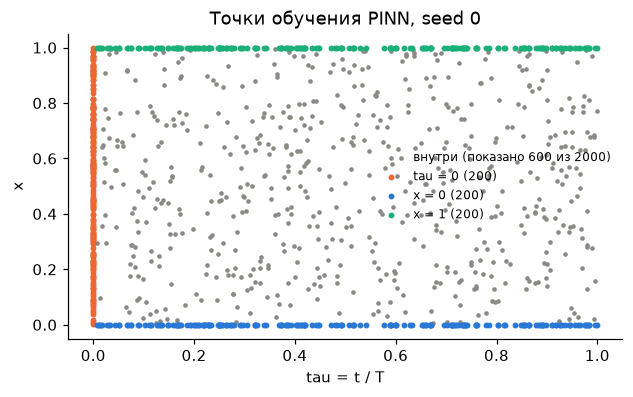

In [8]:
cfg = PINNConfig()
trained_now = ensure_trained(processes=4)  # обучает только то, чего нет в weights/
print("обучено в этом запуске:", len(trained_now), "| всего запусков:", len(all_runs()))

model, main_run = load_run("main_seed0")
n_params = sum(p.numel() for p in model.parameters())
print(model.net)
print("параметров сети:", n_params)

# Превью точек, на которых учится сеть: у PINN это и есть обучающие данные
points = sample_points(cfg, torch.Generator().manual_seed(cfg.seed))
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.scatter(points["tau_r"][:600], points["x_r"][:600], s=4, color=COLORS["steady"], label=f"внутри (показано 600 из {cfg.n_interior})")
ax.scatter(np.zeros(cfg.n_initial), points["x_ic"], s=8, color=COLORS["euler"], label=f"tau = 0 ({cfg.n_initial})")
ax.scatter(points["tau_b"], np.zeros(cfg.n_boundary), s=8, color=COLORS["pinn"], label=f"x = 0 ({cfg.n_boundary})")
ax.scatter(points["tau_b"], np.ones(cfg.n_boundary), s=8, color=COLORS["aqua"], label=f"x = 1 ({cfg.n_boundary})")
ax.set(xlabel="tau = t / T", ylabel="x", title="Точки обучения PINN, seed 0")
ax.legend(fontsize=8, loc="center right")
ax.grid(False)
save_figure(fig, "c2_sampled_points")

## C3. Потери во время обучения

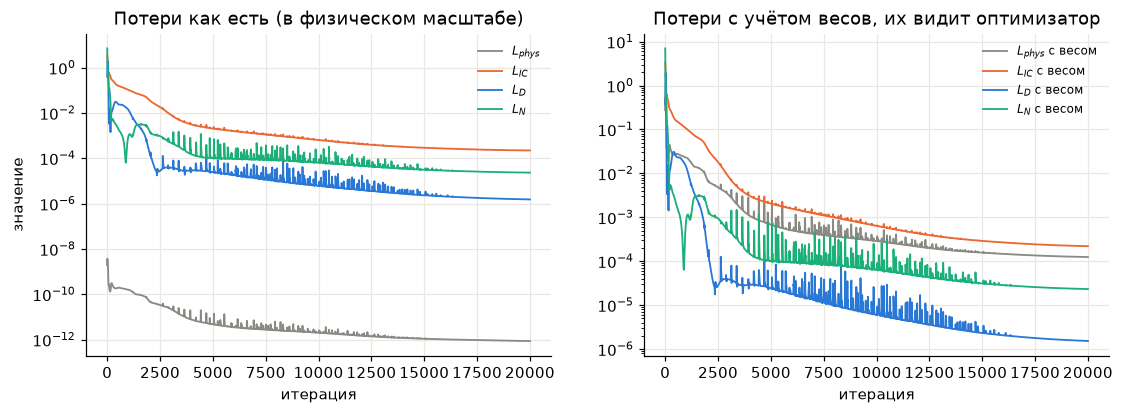

,Настройка,Значение
0,Архитектура,"(x, tau) -> 3 слоя по 32 tanh -> u"
1,Параметров сети,2241
2,Точек внутри / при tau=0 / на каждой границе,2000 / 200 / 200
3,Точки,"равномерные случайные, фиксированы на всё обуч..."
4,Веса physics / IC / D / N,1.44e+08 / 1.0 / 1.0 / 1.0
5,Seed,0
6,Оптимизатор,"Adam, lr 0.001 -> 1e-05 по косинусу"
7,Итераций,20000
8,"Время обучения, с (1 поток CPU, Apple M4)",3.584e+02


,часть,без веса,вес,с весом,"старт, без веса"
0,physics,8.743e-13,1.440e+08,1.259e-04,1.909e-09
1,initial,2.230e-04,1.000e+00,2.230e-04,3.354e+00
2,dirichlet,1.560e-06,1.000e+00,1.560e-06,3.844e-01
3,neumann,2.357e-05,1.000e+00,2.357e-05,7.014e+00


In [9]:
history = main_run["history"]
names = {"physics": "$L_{phys}$", "initial": "$L_{IC}$", "dirichlet": "$L_D$", "neumann": "$L_N$"}
line_colors = {"physics": COLORS["steady"], "initial": COLORS["euler"], "dirichlet": COLORS["pinn"], "neumann": COLORS["aqua"]}
weights = {"physics": cfg.weight_physics, "initial": cfg.weight_initial, "dirichlet": cfg.weight_dirichlet, "neumann": cfg.weight_neumann}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
for name, label in names.items():
    axes[0].semilogy(history["iteration"], history[name], lw=1.2, color=line_colors[name], label=label)
    axes[1].semilogy(history["iteration"], weights[name] * history[name], lw=1.2, color=line_colors[name], label=f"{label} с весом")
axes[0].set(title="Потери как есть (в физическом масштабе)", xlabel="итерация", ylabel="значение")
axes[1].set(title="Потери с учётом весов, их видит оптимизатор", xlabel="итерация")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
save_figure(fig, "c3_losses")

settings = pd.DataFrame([
    ("Архитектура", f"(x, tau) -> {cfg.hidden_layers} слоя по {cfg.hidden_units} tanh -> u"),
    ("Параметров сети", n_params),
    ("Точек внутри / при tau=0 / на каждой границе", f"{cfg.n_interior} / {cfg.n_initial} / {cfg.n_boundary}"),
    ("Точки", "равномерные случайные, фиксированы на всё обучение"),
    ("Веса physics / IC / D / N", f"{cfg.weight_physics:.3g} / {cfg.weight_initial} / {cfg.weight_dirichlet} / {cfg.weight_neumann}"),
    ("Seed", cfg.seed),
    ("Оптимизатор", f"Adam, lr {cfg.lr} -> {cfg.lr_final} по косинусу"),
    ("Итераций", cfg.iterations),
    ("Время обучения, с (1 поток CPU, Apple M4)", round(main_run["seconds"], 1)),
], columns=["Настройка", "Значение"])
save_table(settings, "c3_settings")

final = pd.DataFrame([{"часть": name, "без веса": np.mean(history[name][-100:]), "вес": weights[name],
                       "с весом": weights[name] * np.mean(history[name][-100:]),
                       "старт, без веса": history[name][0]} for name in names])
save_table(final, "c3_final_losses")

In [10]:
# Контроль без точного решения: все потери на независимых точках, которых сеть не видела
fresh = torch.Generator().manual_seed(12345)
fresh_points = {"x_r": torch.rand(50000, 1, generator=fresh, dtype=DTYPE), "tau_r": torch.rand(50000, 1, generator=fresh, dtype=DTYPE),
                "x_ic": torch.rand(20000, 1, generator=fresh, dtype=DTYPE), "tau_b": torch.rand(20000, 1, generator=fresh, dtype=DTYPE)}
corner = (fresh_points["tau_r"] < 0.02) & (fresh_points["x_r"] > 0.9)  # область рядом с углом (1, 0)
rows = []
for name in ("main_seed0", "main_seed1", "main_seed2", "resample_seed0"):
    m, run = load_run(name)
    terms = loss_terms(m, fresh_points)
    scaled = (T * physics_residual(m, fresh_points["x_r"], fresh_points["tau_r"]).detach()) ** 2
    rows.append({"запуск": name, "T^2 L_phys, обучение": T**2 * np.mean(run["history"]["physics"][-100:]),
                 "T^2 L_phys, свежие": scaled.mean().item(), "свежие, без угла": scaled[~corner].mean().item(),
                 "доля угла в невязке": (scaled[corner].sum() / scaled.sum()).item(),
                 "L_IC, свежие": terms["initial"].item(), "L_D, свежие": terms["dirichlet"].item(), "L_N, свежие": terms["neumann"].item()})
fresh_table = pd.DataFrame(rows)
fresh_table["сумма потерь, свежие"] = fresh_table[["T^2 L_phys, свежие", "L_IC, свежие", "L_D, свежие", "L_N, свежие"]].sum(axis=1)
save_table(fresh_table, "c3_fresh_points_check")

# Влияние числа итераций и веса физики. Один запуск меняет одну настройку
rows = []
for name, label in (("baseline_1000", "1000 итераций"), ("main_seed0", "20000 итераций, вес физики T^2"), ("no_physics_weight", "20000 итераций, вес физики 1")):
    m, run = load_run(name)
    h = run["history"]
    row = {"запуск": label, "L_phys": np.mean(h["physics"][-10:]), "L_IC": np.mean(h["initial"][-10:]),
           "L_D": np.mean(h["dirichlet"][-10:]), "L_N": np.mean(h["neumann"][-10:])}
    for t in ERROR_TIMES:
        row[f"RMSE t={t:.0f}"] = rmse(predict(m, X_EVAL, t), reference(X_EVAL, t))
    rows.append(row)
save_table(pd.DataFrame(rows), "c3_settings_effect")

,запуск,"T^2 L_phys, обучение","T^2 L_phys, свежие","свежие, без угла",доля угла в невязке,"L_IC, свежие","L_D, свежие","L_N, свежие","сумма потерь, свежие"
0,main_seed0,1.259e-04,2.060e-03,5.332e-04,7.420e-01,2.318e-04,1.491e-06,1.376e-04,2.431e-03
1,main_seed1,1.223e-04,8.299e-04,5.589e-04,3.286e-01,6.879e-04,2.547e-06,8.610e-06,1.529e-03
2,main_seed2,1.147e-04,4.947e-04,2.365e-04,5.234e-01,3.570e-04,1.103e-06,1.329e-05,8.661e-04
3,resample_seed0,4.443e-04,4.933e-04,2.786e-04,4.370e-01,1.110e-03,6.675e-06,9.608e-05,1.706e-03


,запуск,L_phys,L_IC,L_D,L_N,RMSE t=3000,RMSE t=6000,RMSE t=12000
0,1000 итераций,1.940e-10,1.566e-01,2.412e-02,1.917e-03,5.851e-02,1.853e-02,2.719e-02
1,"20000 итераций, вес физики T^2",8.641e-13,2.201e-04,1.526e-06,2.323e-05,1.361e-03,1.344e-03,1.197e-03
2,"20000 итераций, вес физики 1",4.218e-07,6.582e-05,5.178e-07,1.544e-05,6.134e-01,7.680e-01,6.234e-01


**Дисбаланс потерь.**
- *Без веса физика не видна.* В начале обучения $L_{\text{N}}\approx7$ и $L_{\text{IC}}\approx3.4$, а $L_{\text{phys}}\approx2\cdot10^{-9}$. Причина в масштабе: $r=\tfrac1Tu_\tau-\beta u_{xx}$ содержит множители $8.3\cdot10^{-5}$ и $10^{-5}$. Это разница масштаба, а не признак того, что уравнение уже выполнено.
- *Что будет без масштабирования.* Запуск с $\lambda_{\text{phys}}=1$ отлично выучил начальное и граничные условия, но $T^2L_{\text{phys}}\approx61$, то есть уравнение не решено. Его RMSE равен 0.61–0.77 и хуже даже стационарного baseline (0.18–0.35). Малый $L_{\text{phys}}=4.2\cdot10^{-7}$ здесь обманчив: важно сравнивать слагаемые в одном масштабе.
- *С весом $T^2$* вклады физики и начального условия становятся одного порядка ($1.3\cdot10^{-4}$ и $2.2\cdot10^{-4}$), оптимизатор учитывает оба. $L_{\text{D}}\approx1.6\cdot10^{-6}$ самый маленький: константу на левой границе выучить проще всего. $L_{\text{IC}}$ остаётся самым большим из-за несогласованности в углу и изгибов синуса.
- *Число итераций.* На базовых 1000 итераций $L_{\text{IC}}\approx0.16$ и RMSE при $t=3000$ равен $5.9\cdot10^{-2}$. Это лучше baseline, но в 6 раз хуже заданной схемы Эйлера. Поэтому в основном запуске 20000 итераций.

**Контроль на свежих точках.** Невязка на независимых точках выше, чем на обучающих: при seed 0 это $2.1\cdot10^{-3}$ против $1.3\cdot10^{-4}$. Значительная часть этого разрыва сидит у угла, куда почти не попадают точки коллокации (доля угла 0.33–0.74 при 0.2% площади). Без угла разрыв остаётся примерно в 2–5 раз, то есть фиксированные точки дают небольшое переобучение. Вариант с пересэмплированием на свежих точках даёт меньшую физическую невязку, чем seed 0, но больший $L_{\text{IC}}$ (сумма потерь $1.7\cdot10^{-3}$). Для основных seed сумма составляет $0.9$–$2.4\cdot10^{-3}$, поэтому **преимущества ни у одного варианта доказать нельзя**: разница не больше разброса между seed. Настройки оставлены прежними, а этот вывод остаётся ограничением работы.

## C4. Сравнение с аналитикой и граничные условия

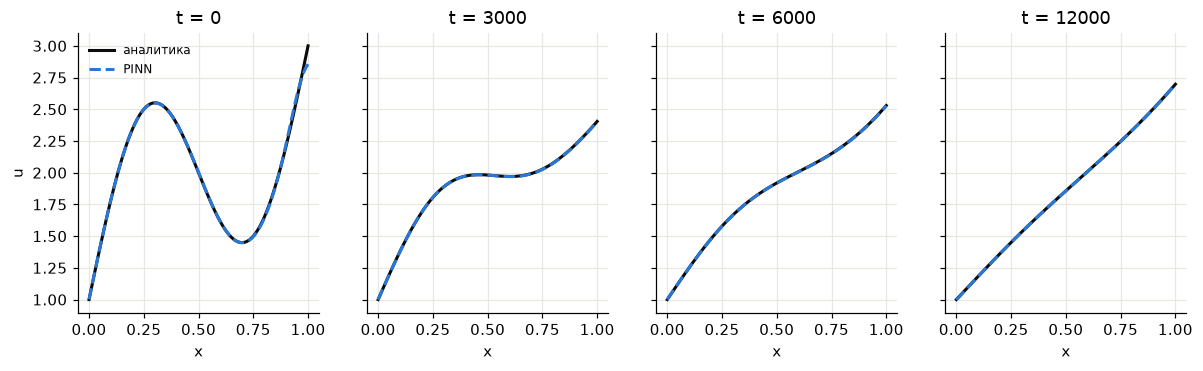

,t,max ошибка,RMSE,"x, где max"
0,0.000e+00,1.445e-01,1.902e-02,1.000e+00
1,3.000e+03,2.435e-03,1.361e-03,9.200e-01
2,6.000e+03,2.156e-03,1.344e-03,9.800e-01
3,1.200e+04,2.954e-03,1.197e-03,0.000e+00


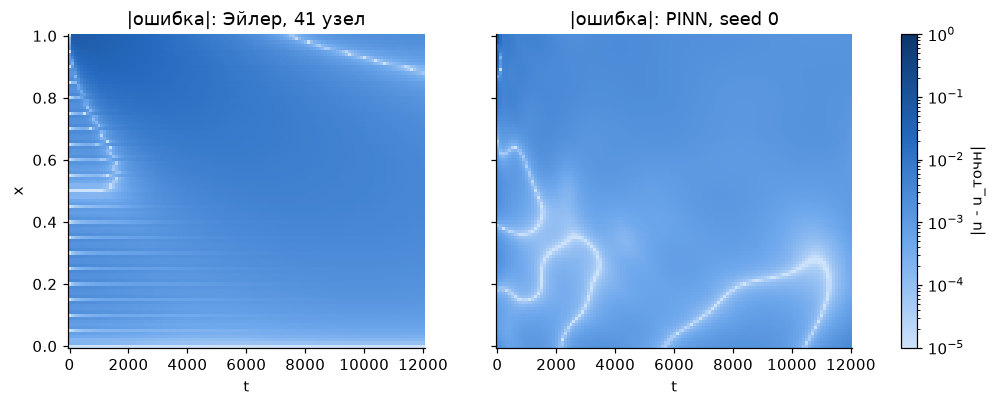

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3), sharey=True)
for ax, t in zip(axes, REPORT_TIMES):
    ax.plot(X_EVAL, reference(X_EVAL, t), color=COLORS["exact"], label="аналитика")
    ax.plot(X_EVAL, predict(model, X_EVAL, t), "--", color=COLORS["pinn"], label="PINN")
    ax.set(title=f"t = {t:.0f}", xlabel="x")
axes[0].set_ylabel("u")
axes[0].legend(loc="upper left", fontsize=8)
save_figure(fig, "c4_pinn_vs_analytic")

rows = []
for t in REPORT_TIMES:
    pred, ref = predict(model, X_EVAL, t), reference(X_EVAL, t)
    rows.append({"t": t, "max ошибка": max_abs_error(pred, ref), "RMSE": rmse(pred, ref), "x, где max": X_EVAL[np.argmax(np.abs(pred - ref))]})
save_table(pd.DataFrame(rows), "c4_pinn_errors")

# Карта абсолютной ошибки PINN и Эйлера на общей сетке
times_map = np.linspace(0, T, 121)
exact_map = np.array([reference(X_EVAL, t) for t in times_map])
pinn_map = np.array([predict(model, X_EVAL, t) for t in times_map])
euler_map = np.array([np.interp(X_EVAL, x_c, profile_at(t_c, U_c, t)) for t in times_map])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7), sharey=True)
norm = LogNorm(vmin=1e-5, vmax=1)
for ax, field, title in ((axes[0], euler_map, "Эйлер, 41 узел"), (axes[1], pinn_map, "PINN, seed 0")):
    image = ax.pcolormesh(times_map, X_EVAL, np.abs(field - exact_map).T + 1e-12, cmap=BLUES, norm=norm, shading="auto")
    ax.set(title=f"|ошибка|: {title}", xlabel="t")
    ax.grid(False)
axes[0].set_ylabel("x")
fig.colorbar(image, ax=axes, label="|u - u_точн|")
save_figure(fig, "c4_error_maps")

,проверка,max|.|,RMS
0,"PINN: u(0,t) - 1",2.954e-03,1.216e-03
1,"PINN: u_x(1,t) - 2, автоград",3.016e-02,4.219e-03
2,Эйлер: U_0 - 1,0.000e+00,0.000e+00
3,Эйлер: (U_J - U_{J-1})/dx - 2,7.105e-15,7.105e-15
4,Эйлер: наклон 2-го порядка - 2,1.227e+00,1.662e-01


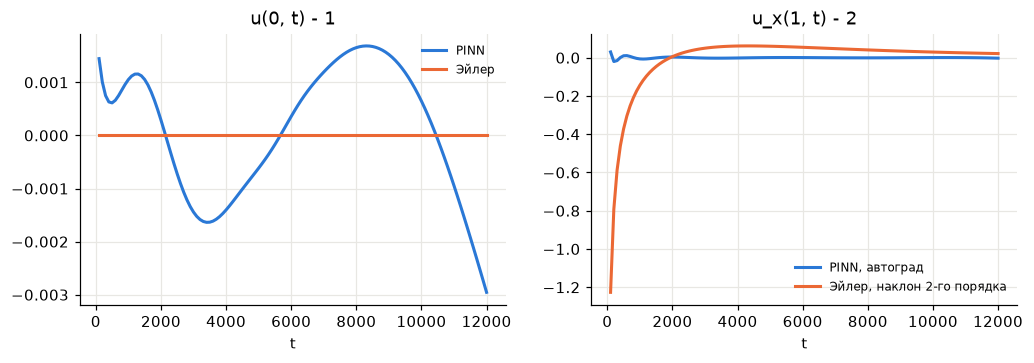

In [12]:
# Проверка граничных условий на общей сетке времени, t > 0
times_bc = np.linspace(100, T, 120)
left_pinn, right_pinn = boundary_residuals(model, times_bc)
index = np.round(times_bc / (t_c[1] - t_c[0])).astype(int)
dx_c = x_c[1] - x_c[0]
left_euler = U_c[index, 0] - 1.0
one_sided = (U_c[index, -1] - U_c[index, -2]) / dx_c - 2.0  # то, что схема обнуляет по построению
second_order = (3 * U_c[index, -1] - 4 * U_c[index, -2] + U_c[index, -3]) / (2 * dx_c) - 2.0  # более точная оценка наклона

def bc_row(label, values):
    return {"проверка": label, "max|.|": np.abs(values).max(), "RMS": np.sqrt(np.mean(values**2))}

bc_table = pd.DataFrame([
    bc_row("PINN: u(0,t) - 1", left_pinn),
    bc_row("PINN: u_x(1,t) - 2, автоград", right_pinn),
    bc_row("Эйлер: U_0 - 1", left_euler),
    bc_row("Эйлер: (U_J - U_{J-1})/dx - 2", one_sided),
    bc_row("Эйлер: наклон 2-го порядка - 2", second_order),
])
save_table(bc_table, "c4_boundary_residuals")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharex=True)
axes[0].plot(times_bc, left_pinn, color=COLORS["pinn"], label="PINN")
axes[0].plot(times_bc, left_euler, color=COLORS["euler"], label="Эйлер")
axes[0].set(title="u(0, t) - 1", xlabel="t")
axes[1].plot(times_bc, right_pinn, color=COLORS["pinn"], label="PINN, автоград")
axes[1].plot(times_bc, second_order, color=COLORS["euler"], label="Эйлер, наклон 2-го порядка")
axes[1].set(title="u_x(1, t) - 2", xlabel="t")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
save_figure(fig, "c4_boundary_residuals")

**Вывод.**
- **Профили.** При $t\ge3000$ PINN на глаз совпадает с аналитикой, RMSE $1.2$–$1.4\cdot10^{-3}$, максимум $2$–$3\cdot10^{-3}$.
- **Начальный момент.** При $t=0$ максимальная ошибка 0.145 находится точно в $x=1$. Это проявление несогласованности в углу из раздела 2, RMSE при этом $1.9\cdot10^{-2}$. Карта ошибок показывает разный характер: у Эйлера ошибка рождается у правого края на ранних временах и затем расходится внутрь, а у PINN она распределена по области без такой структуры, с линиями смены знака.
- **Граничные условия.** У PINN они выполнены только приближённо: $u(0,t)-1$ имеет RMS $1.2\cdot10^{-3}$ и максимум $3\cdot10^{-3}$. При $t=12000$ самая большая ошибка профиля как раз находится в $x=0$. $u_x(1,t)-2$ имеет RMS $4.2\cdot10^{-3}$ и максимум $3\cdot10^{-2}$ (на $t\ge100$).
- **Эйлер для сравнения.** Левое условие выполнено точно, а односторонняя разность справа обнуляется по построению, поэтому ноль там ничего не доказывает. Более честная оценка наклона второго порядка даёт RMS 0.17 и максимум 1.2 при $t=100$. Она сама считается на грубой сетке, поэтому это оценка, а не точное значение.

---
# Часть D. Сравнение методов
Общая сетка: $x_i=i/100$, $i=0,\dots,100$, всего $M=101$ точка. Эталон: ряд из $N=2000$ слагаемых. При $t\ge3000$ он сошёлся до машинной точности (таблица A4).

## D1. Таблица ошибок
**Определение метрик** для метода с предсказанием $\hat u$ в момент $t$:

$$E_{\max}(t)=\max_{1\le i\le M}\big|\hat u(x_i,t)-u_{\text{ser}}(x_i,t)\big|,\qquad\mathrm{RMSE}(t)=\sqrt{\frac1M\sum_{i=1}^{M}\big(\hat u(x_i,t)-u_{\text{ser}}(x_i,t)\big)^2}.$$

$E_{\max}$ показывает худшую точку и чувствителен к проблемам у границ, RMSE показывает среднюю ошибку по всему профилю.

In [13]:
def error_row(label, predictor):
    row = {"метод": label}
    for t in ERROR_TIMES:
        pred = predictor(t)
        row[f"max t={t:.0f}"] = max_abs_error(pred, reference(X_EVAL, t))
        row[f"RMSE t={t:.0f}"] = rmse(pred, reference(X_EVAL, t))
    return row

x_f, t_f, U_f = solve_euler(160, 9600, 1, store_every=2400)
x_2, t_2, U_2 = solve_euler(40, 600, 2, store_every=150)  # та же сетка, Нейман 2-го порядка

d1 = pd.DataFrame([
    error_row("Эйлер, dx=1/40, dt=20", lambda t: np.interp(X_EVAL, x_c, profile_at(t_c, U_c, t))),
    error_row("PINN, seed 0, 20000 итераций", lambda t: predict(model, X_EVAL, t)),
])
save_table(d1, "d1_errors_main")

seed_models = {seed: load_run(f"main_seed{seed}")[0] for seed in SEEDS}
seed_rows = [error_row(f"seed {seed}", lambda t, m=m: predict(m, X_EVAL, t)) for seed, m in seed_models.items()]
seed_frame = pd.DataFrame(seed_rows)
numeric = seed_frame.drop(columns="метод")

extended = pd.DataFrame([
    error_row("baseline: u_s(x)", lambda t: steady_state(X_EVAL)),
    error_row("Эйлер, dx=1/40, dt=20", lambda t: np.interp(X_EVAL, x_c, profile_at(t_c, U_c, t))),
    error_row("Эйлер, dx=1/40, dt=20, Нейман 2-го порядка", lambda t: np.interp(X_EVAL, x_2, profile_at(t_2, U_2, t))),
    error_row("Эйлер, dx=1/160, dt=1.25", lambda t: np.interp(X_EVAL, x_f, profile_at(t_f, U_f, t))),
    error_row("PINN, 1000 итераций", lambda t: predict(load_run("baseline_1000")[0], X_EVAL, t)),
    {"метод": "PINN, среднее по 3 seed", **numeric.mean().to_dict()},
    {"метод": "PINN, разброс (std) по 3 seed", **numeric.std().to_dict()},
])
save_table(extended, "d1_errors_extended")

,метод,max t=3000,RMSE t=3000,max t=6000,RMSE t=6000,max t=12000,RMSE t=12000
0,"Эйлер, dx=1/40, dt=20",1.995e-02,9.337e-03,8.519e-03,5.173e-03,3.381e-03,2.284e-03
1,"PINN, seed 0, 20000 итераций",2.435e-03,1.361e-03,2.156e-03,1.344e-03,2.954e-03,1.197e-03


,метод,max t=3000,RMSE t=3000,max t=6000,RMSE t=6000,max t=12000,RMSE t=12000
0,baseline: u_s(x),5.958e-01,3.522e-01,4.707e-01,2.488e-01,3.028e-01,1.825e-01
1,"Эйлер, dx=1/40, dt=20",1.995e-02,9.337e-03,8.519e-03,5.173e-03,3.381e-03,2.284e-03
2,"Эйлер, dx=1/40, dt=20, Нейман 2-го порядка",1.562e-03,9.889e-04,1.182e-03,6.502e-04,8.066e-04,4.125e-04
3,"Эйлер, dx=1/160, dt=1.25",5.907e-03,2.777e-03,2.751e-03,1.675e-03,1.160e-03,8.013e-04
4,"PINN, 1000 итераций",1.682e-01,5.851e-02,3.485e-02,1.853e-02,7.246e-02,2.719e-02
5,"PINN, среднее по 3 seed",2.461e-03,1.336e-03,2.154e-03,1.193e-03,1.973e-03,9.569e-04
6,"PINN, разброс (std) по 3 seed",7.438e-04,5.017e-04,1.145e-03,6.699e-04,9.786e-04,4.926e-04


**Вывод.**
- **Заданные методы.** PINN с seed 0 точнее заданной схемы Эйлера: по RMSE в 6.9 раза при $t=3000$, в 3.8 раза при $t=6000$, в 1.9 раза при $t=12000$. По максимуму разрыв при $t=12000$ почти исчезает ($3.0\cdot10^{-3}$ против $3.4\cdot10^{-3}$). Преимущество PINN падает со временем, так как ошибка Эйлера затухает вместе с ранним пограничным слоем.
- **Откуда этот выигрыш.** Он в основном объясняется условием первого порядка, а не превосходством сети. Эйлер на той же сетке с условием второго порядка точнее среднего PINN во всех трёх моментах и по RMSE, и по максимуму (лучший из трёх seed по RMSE немного его опережает). Сетка $1/160$ по RMSE находится в пределах двух раз от PINN.
- **Минимальный PINN.** С 1000 итераций он в 3–12 раз хуже заданной схемы Эйлера.
- **Случайность.** Разброс PINN по 3 seed составляет около 40–55% от среднего, при этом seed 2 в разы точнее seed 0. Схема Эйлера детерминирована, разброса у неё нет. Seed 0 назначен заранее и не выбирался по результату.

## D2. Сравнение по профилям, стоимости, границам и чувствительности

In [14]:
# Стоимость расчёта. Для Эйлера берём медиану из 5 повторов
euler_times = []
for _ in range(5):
    start = time.perf_counter()
    solve_euler(40, 600, 1, store_every=150)
    euler_times.append(time.perf_counter() - start)

start = time.perf_counter()
for t in ERROR_TIMES:
    predict(model, X_EVAL, t)
pinn_inference = (time.perf_counter() - start) / len(ERROR_TIMES)

start = time.perf_counter()
for t in ERROR_TIMES:
    np.interp(X_EVAL, x_c, profile_at(t_c, U_c, t))
euler_inference = (time.perf_counter() - start) / len(ERROR_TIMES)

def rmse_at(predictor, t=3000.0):
    return rmse(predictor(t), reference(X_EVAL, t))

def euler_cost(label, n_intervals, order):
    # Время и ошибка берутся из таблицы измельчения B4
    row = refine[(refine["dx"] == 1 / n_intervals) & (refine["порядок Неймана"] == order)].iloc[0]
    steps = int(round(T / row["dt"]))
    return {"метод": label, "обучение или расчёт, с": row["время, с"], "запрос профиля 101 точка, с": euler_inference,
            "чисел хранить (все слои)": (n_intervals + 1) * (steps + 1), "RMSE t=3000": row["RMSE t=3000"]}

cost = pd.DataFrame([
    euler_cost("Эйлер, dx=1/40", 40, 1),
    euler_cost("Эйлер, dx=1/40, Нейман 2-го порядка", 40, 2),
    euler_cost("Эйлер, dx=1/160", 160, 1),
    euler_cost("Эйлер, dx=1/320", 320, 1),
    {"метод": "PINN, 20000 итераций", "обучение или расчёт, с": main_run["seconds"], "запрос профиля 101 точка, с": pinn_inference,
     "чисел хранить (все слои)": n_params, "RMSE t=3000": rmse_at(lambda t: predict(model, X_EVAL, t))},
])
save_table(cost, "d2_cost")
print("Медиана 5 повторов Эйлера dx=1/40, с:", round(np.median(euler_times), 5))
print("Во сколько раз обучение PINN дольше расчёта Эйлера на заданной сетке:", round(main_run["seconds"] / np.median(euler_times)))
print("То же против Эйлера dx=1/320 с той же ошибкой при t=3000:", round(main_run["seconds"] / cost["обучение или расчёт, с"].iloc[3]))

# Сравнение значения на правом конце: здесь сказывается условие Неймана
rows = []
for t in ERROR_TIMES:
    ref_right = reference(np.array([1.0]), t)[0]
    rows.append({"t": t, "u(1,t) точное": ref_right,
                 "|Эйлер - точное|": abs(profile_at(t_c, U_c, t)[-1] - ref_right),
                 "|PINN - точное|": abs(predict(model, np.array([1.0]), t)[0] - ref_right),
                 "|PINN(x=0) - 1|": abs(predict(model, np.array([0.0]), t)[0] - 1.0), "|Эйлер(x=0) - 1|": 0.0})
save_table(pd.DataFrame(rows), "d2_right_end")

,метод,"обучение или расчёт, с","запрос профиля 101 точка, с",чисел хранить (все слои),RMSE t=3000
0,"Эйлер, dx=1/40",1.981e-03,3.176e-05,24641,9.337e-03
1,"Эйлер, dx=1/40, Нейман 2-го порядка",2.122e-03,3.176e-05,24641,9.889e-04
2,"Эйлер, dx=1/160",3.374e-02,3.176e-05,1545761,2.777e-03
3,"Эйлер, dx=1/320",1.407e-01,3.176e-05,12326721,1.424e-03
4,"PINN, 20000 итераций",3.584e+02,3.145e-04,2241,1.361e-03


Медиана 5 повторов Эйлера dx=1/40, с: 0.00192
Во сколько раз обучение PINN дольше расчёта Эйлера на заданной сетке: 187045
То же против Эйлера dx=1/320 с той же ошибкой при t=3000: 2548


,t,"u(1,t) точное",|Эйлер - точное|,|PINN - точное|,|PINN(x=0) - 1|,|Эйлер(x=0) - 1|
0,3.000e+03,2.404e+00,1.857e-02,2.283e-03,1.443e-03,0.000e+00
1,6.000e+03,2.529e+00,2.891e-03,2.143e-03,3.570e-04,0.000e+00
2,1.200e+04,2.697e+00,2.315e-03,1.585e-03,2.954e-03,0.000e+00


### Ранние времена и угол $(1,0)$
Ожидание до расчёта: у Эйлера ошибка сидит рядом с $x=1$ и падает, когда слой толщиной $\sqrt{\beta t}$ становится шире шага сетки. У PINN при $t\to0$ ошибка должна концентрироваться в том же углу.

,t,sqrt(beta t),max Эйлер 1/40,x (Эйлер 1/40),max Эйлер 1/160,max PINN,x (PINN),RMSE PINN
0,0.000e+00,0.000e+00,2.951e-03,7.400e-01,1.847e-04,1.445e-01,1.000e+00,1.902e-02
1,2.000e+01,1.414e-02,5.546e-02,1.000e+00,1.831e-02,6.417e-02,1.000e+00,1.125e-02
2,1.000e+02,3.162e-02,6.591e-02,1.000e+00,1.829e-02,1.674e-02,1.000e+00,3.591e-03
3,5.000e+02,7.071e-02,5.819e-02,1.000e+00,1.574e-02,6.001e-03,9.800e-01,2.455e-03
4,1.000e+03,1.000e-01,4.701e-02,1.000e+00,1.287e-02,4.330e-03,1.000e+00,1.954e-03
5,3.000e+03,1.732e-01,1.995e-02,9.500e-01,5.907e-03,2.435e-03,9.200e-01,1.361e-03


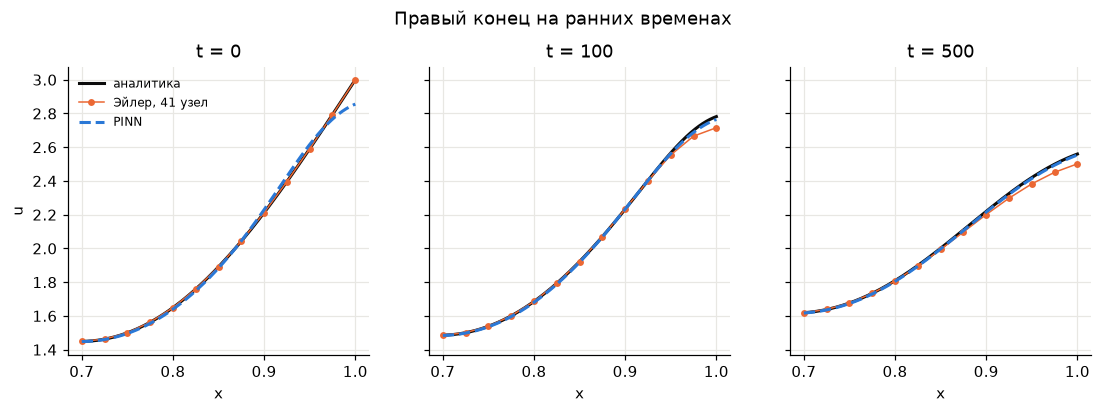

In [15]:
early = [0.0, 20.0, 100.0, 500.0, 1000.0, 3000.0]
x_e, t_e, U_e = solve_euler(160, 9600, 1, store_every=16)  # шаг сохранения 20, как на грубой сетке
rows = []
for t in early:
    ref = reference(X_EVAL, t)
    euler_c = np.interp(X_EVAL, x_c, profile_at(t_c, U_c, t))
    euler_f = np.interp(X_EVAL, x_e, profile_at(t_e, U_e, t))
    pinn_p = predict(model, X_EVAL, t)
    rows.append({"t": t, "sqrt(beta t)": np.sqrt(BETA * t),
                 "max Эйлер 1/40": max_abs_error(euler_c, ref), "x (Эйлер 1/40)": X_EVAL[np.argmax(np.abs(euler_c - ref))],
                 "max Эйлер 1/160": max_abs_error(euler_f, ref),
                 "max PINN": max_abs_error(pinn_p, ref), "x (PINN)": X_EVAL[np.argmax(np.abs(pinn_p - ref))],
                 "RMSE PINN": rmse(pinn_p, ref)})
save_table(pd.DataFrame(rows), "d2_early_times")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
x_zoom = np.linspace(0.7, 1.0, 301)
for ax, t in zip(axes, (0.0, 100.0, 500.0)):
    ax.plot(x_zoom, reference(x_zoom, t), color=COLORS["exact"], label="аналитика")
    ax.plot(x_c[x_c >= 0.7 - 1e-9], profile_at(t_c, U_c, t)[x_c >= 0.7 - 1e-9], "o-", ms=3.5, lw=1, color=COLORS["euler"], label="Эйлер, 41 узел")
    ax.plot(x_zoom, predict(model, x_zoom, t), "--", color=COLORS["pinn"], label="PINN")
    ax.set(title=f"t = {t:.0f}", xlabel="x")
axes[0].set_ylabel("u")
axes[0].legend(fontsize=8)
fig.suptitle("Правый конец на ранних временах", y=1.03)
save_figure(fig, "d2_early_corner")

**Вывод по пунктам D2.**

| Критерий | Явный Эйлер | PINN |
|---|---|---|
| **Профили** | Совпадают с аналитикой, заметное отличие только у правого конца на ранних временах | Совпадают при $t\ge100$, наибольшая ошибка при малых $t$ в $x=1$ |
| **Стоимость** | 2–3 мс на заданной сетке, 0.1–0.2 с на сетке $1/320$ | Около 6 минут обучения на том же CPU, затем меньше 1 мс на профиль |
| **Хранение** | Решение только в узлах, нужна интерполяция | 2241 число, непрерывная функция с точными производными |
| **Границы** | Дирихле точно, Нейман с ошибкой $O(\Delta x)$ | Оба условия приближённо, штрафом |
| **Чувствительность** | Детерминирована, есть теория: $s\le\frac12$, известный порядок | Зависит от весов, итераций и seed, теоретической оценки ошибки нет |

**Стоимость.** Обучение PINN примерно в $10^5$ раз дольше расчёта на заданной сетке. Если сравнивать при равной ошибке (RMSE около $1.4\cdot10^{-3}$ при $t=3000$), то Эйлер на сетке $1/320$ всё ещё быстрее более чем в 1000 раз. По числу операций шаг измельчения стоит в 8 раз больше (в 4 раза больше шагов и в 2 раза больше узлов), а измеренное время растёт примерно в 4 раза: на таких маленьких массивах основное время занимает цикл Python.

**Чувствительность PINN.** Сеть выходит на нужную точность только при подходящих настройках: без масштабирования физики RMSE равен 0.6–0.8, при 1000 итераций около $6\cdot10^{-2}$. Значение loss при этом нельзя напрямую перевести в ошибку решения, а у Эйлера порядок ошибки известен заранее.

**Ранние времена.** Для схемы $1/40$ ошибка максимальна в $x=1$ и держится на уровне 0.05–0.07 при $t=20$–$500$, потому что ошибка границы $\frac{\Delta x}{2}u_{xx}(1,t)$ велика, пока слой тонкий. На сетке $1/160$ она в 3–4 раза меньше. У PINN картина другая: 0.145 при $t=0$ и 0.064 при $t=20$, это уровень грубого Эйлера или хуже, но уже при $t=100$ ошибка равна $1.7\cdot10^{-2}$ и дальше падает быстрее. Сравнение при малых $t$ поэтому нельзя переносить на всё время: оно в основном говорит о том, как метод обходится с разрывом наклона. Кроме того, при $t=0$ Эйлер точен в узлах просто по построению.

**Где PINN действительно полезен.** Эта задача одномерная и линейная, поэтому численной схеме здесь трудно проиграть. Сильные стороны PINN проявляются в другом: не нужна сетка, легко добавить измерения в loss и искать неизвестные параметры (например, $\beta$), стоимость не растёт так резко с размерностью. Эти преимущества в данной работе не проверялись и приведены как известные свойства метода.

## D3. Контролируемый эксперимент: вес граничных потерь
**Что меняем:** только $\lambda_b=\lambda_{\text{D}}=\lambda_{\text{N}}\in\{0.1,1,10,100\}$. **Что фиксировано:** архитектура, число итераций, шаг обучения, точки, веса физики и начального условия. Для каждого значения 3 seed, чтобы отличить эффект от случайного разброса.

**Ожидание до расчёта:** при малом $\lambda_b$ сеть хуже держит границы. При большом $\lambda_b$ границы выполняются точнее, но оптимизатор меньше внимания уделяет физике и начальному условию. Ожидается оптимум где-то в середине.

,lambda_b,L_IC,T^2 L_phys,"RMS u(0,t)-1","RMS u_x(1,t)-2",RMSE t=3000,RMSE t=6000,RMSE t=12000,std RMSE t=3000,std RMSE t=6000,std RMSE t=12000
0,1.000e-01,2.793e-04,1.231e-04,2.261e-03,1.368e-02,1.438e-03,1.275e-03,1.258e-03,7.226e-04,5.638e-04,3.808e-04
1,1.000e+00,3.689e-04,1.210e-04,1.289e-03,3.148e-03,1.336e-03,1.193e-03,9.569e-04,5.017e-04,6.699e-04,4.926e-04
2,1.000e+01,1.444e-03,4.589e-04,7.621e-04,1.844e-03,2.187e-03,1.996e-03,1.811e-03,4.367e-04,9.297e-04,6.121e-04
3,1.000e+02,3.921e-02,7.033e-03,1.408e-03,1.559e-03,2.270e-02,1.302e-02,8.575e-03,1.069e-02,8.017e-03,6.179e-03


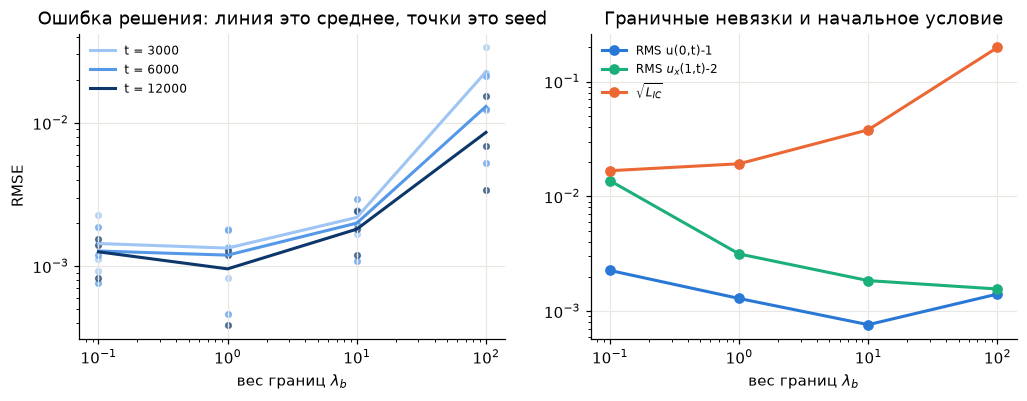

In [16]:
rows = []
for weight in BOUNDARY_WEIGHTS:
    for seed in SEEDS:
        name = f"main_seed{seed}" if weight == 1.0 else f"boundary{weight:g}_seed{seed}"
        m, run = load_run(name)
        left, right = boundary_residuals(m, times_bc)
        row = {"lambda_b": weight, "seed": seed, "L_IC": np.mean(run["history"]["initial"][-100:]),
               "T^2 L_phys": T**2 * np.mean(run["history"]["physics"][-100:]),
               "RMS u(0,t)-1": np.sqrt(np.mean(left**2)), "RMS u_x(1,t)-2": np.sqrt(np.mean(right**2))}
        for t in ERROR_TIMES:
            row[f"RMSE t={t:.0f}"] = rmse(predict(m, X_EVAL, t), reference(X_EVAL, t))
        rows.append(row)
d3_all = pd.DataFrame(rows)
d3_all.to_csv(TABLES / "d3_boundary_weight_all_seeds.csv", index=False)
summary_columns = [c for c in d3_all.columns if c not in ("lambda_b", "seed")]
d3_mean = d3_all.groupby("lambda_b")[summary_columns].mean().reset_index()
d3_std = d3_all.groupby("lambda_b")[[f"RMSE t={t:.0f}" for t in ERROR_TIMES]].std().add_prefix("std ").reset_index()
save_table(d3_mean.merge(d3_std, on="lambda_b"), "d3_boundary_weight_summary")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for t, color in zip(ERROR_TIMES, ("#9ec5f4", "#5598e7", "#0d366b")):
    column = f"RMSE t={t:.0f}"
    axes[0].scatter(d3_all["lambda_b"], d3_all[column], s=14, color=color, alpha=0.6)
    axes[0].plot(d3_mean["lambda_b"], d3_mean[column], color=color, label=f"t = {t:.0f}")
axes[0].set(xscale="log", yscale="log", xlabel="вес границ $\\lambda_b$", ylabel="RMSE", title="Ошибка решения: линия это среднее, точки это seed")
axes[0].legend(fontsize=8)
axes[1].plot(d3_mean["lambda_b"], d3_mean["RMS u(0,t)-1"], "o-", color=COLORS["pinn"], label="RMS u(0,t)-1")
axes[1].plot(d3_mean["lambda_b"], d3_mean["RMS u_x(1,t)-2"], "o-", color=COLORS["aqua"], label="RMS $u_x$(1,t)-2")
axes[1].plot(d3_mean["lambda_b"], np.sqrt(d3_mean["L_IC"]), "o-", color=COLORS["euler"], label="$\\sqrt{L_{IC}}$")
axes[1].set(xscale="log", yscale="log", xlabel="вес границ $\\lambda_b$", title="Граничные невязки и начальное условие")
axes[1].legend(fontsize=8)
save_figure(fig, "d3_boundary_weight")

**Вывод.**
- **Граничные условия ведут себя как ожидалось.** С ростом $\lambda_b$ от 0.1 до 100 RMS $u_x(1,t)-2$ падает с $1.4\cdot10^{-2}$ до $1.6\cdot10^{-3}$. Для $u(0,t)-1$ картина немонотонна: лучшее значение $7.6\cdot10^{-4}$ при $\lambda_b=10$.
- **Цена большого веса.** При $\lambda_b=100$ оптимизатор почти перестаёт учить остальное: $L_{\text{IC}}$ вырастает в 100 раз ($3.9\cdot10^{-2}$ против $3.7\cdot10^{-4}$), а RMSE при $t=3000$ в 17 раз ($2.3\cdot10^{-2}$ против $1.3\cdot10^{-3}$).
- **Малые значения почти равнозначны.** Между $\lambda_b=0.1$ и $1$ разница RMSE ($1.44$ и $1.34\cdot10^{-3}$ при $t=3000$) меньше разброса между seed ($\sim6\cdot10^{-4}$), а $\lambda_b=10$ примерно в 1.6 раза хуже, почти на границе разброса. Поэтому ожидаемого чёткого оптимума нет, уверенно можно сказать только, что $\lambda_b=100$ заметно хуже. Три seed мало для более тонких выводов.
- **Интерпретация.** Точность решения определяется балансом всех слагаемых, а не точностью границ отдельно. Сама по себе малая граничная невязка не гарантирует малой ошибки в области, что и показывает $\lambda_b=100$. Значение $\lambda_b=1$ оставлено основным заранее, а не выбрано по этой таблице.

---
# Итог
- **Аналитика.** $u(x,t)=2x+1+\sum b_n\sin(k_nx)e^{-\beta k_n^2t}$ с $b_n=(-1)^{n+1}4\pi/(4\pi^2-k_n^2)$. Это эталон: при $t\ge3000$ ряд сходится до машинной точности уже при малых $N$. Стационарный профиль при $t=T$ ещё не достигнут ($\max|v|=0.30$).
- **Эйлер.** Самый простой и самый дешёвый метод, $s=0.32$ устойчиво. Заданная схема имеет первый порядок из-за граничного условия: RMSE $9.3\cdot10^{-3}$ при $t=3000$ за 2–3 мс. Замена только граничной формулы даёт второй порядок и ошибку в 9 раз меньше.
- **PINN.** После масштабирования физики и 20000 итераций RMSE около $10^{-3}$, что точнее заданной схемы Эйлера, но примерно равно схеме на сетке $1/160$–$1/320$ и уступает схеме второго порядка на сетке $1/40$. Цена: около 6 минут обучения, зависимость от настроек и seed, приближённое выполнение границ.
- **Главный вывод.** Для этой задачи классическая схема лучше по соотношению точности и стоимости. PINN показал, что может решить задачу без меток, но его результат зависит от масштабирования и настроек, а проверить его без эталона сложнее. Выигрыш у базовой схемы Эйлера объясняется её граничным условием первого порядка, а не превосходством нейросети.

**Ограничения.** Измерения времени сделаны на одной машине, один раз для PINN (Apple M4, один поток CPU). Разброс по 3 seed даёт только грубую оценку случайности обучения. Настройки PINN подбирались небольшим ручным перебором только для этой задачи, другая постановка потребует нового подбора.